# <font color='#35BBCA'>**Step 1: Import Modules**</font>

In [22]:
!pip install nltk spacy
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [23]:
import re
import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer


nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

# <font color='#35BBCA'>**Step 2: Raw Text Collection**</font>

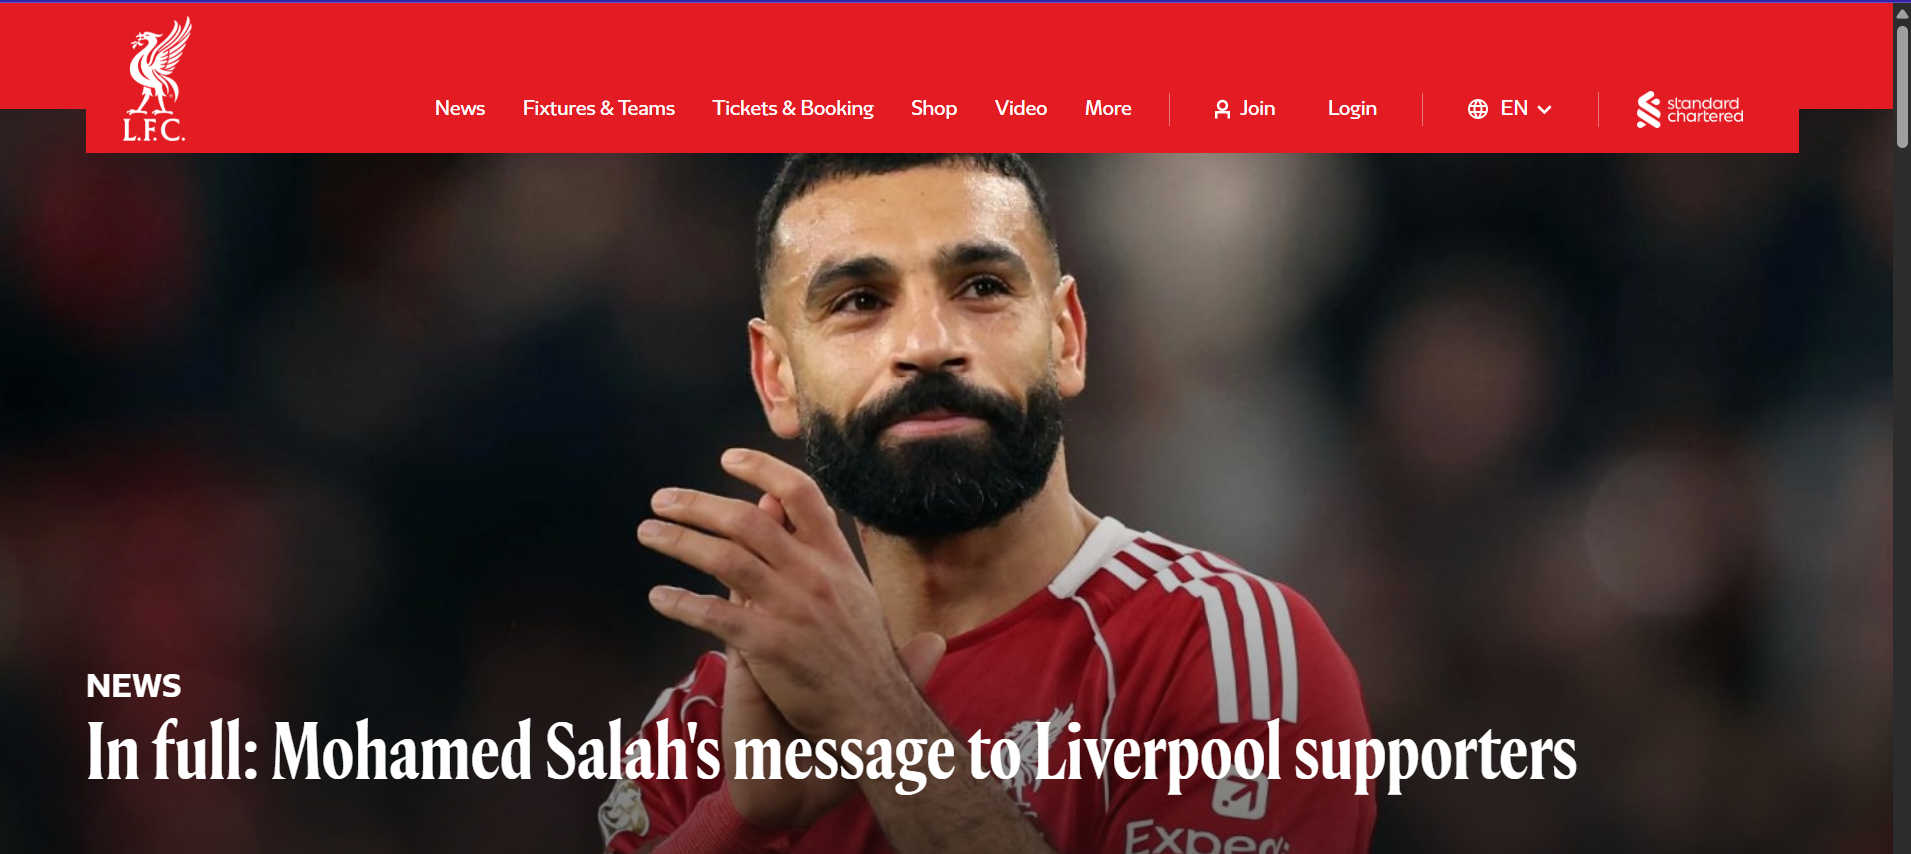

# <mark style="background-color: #9d2933">**The following text was collected from Mohamed Salah's Farewell Speech**</mark>

**[Source:** https://www.liverpoolfc.com/news/full-mohamed-salahs-message-liverpool-supporters **]**

In [24]:
raw_text = """
The Egyptian forward will bid farewell upon the conclusion of his ninth campaign as a Red and as one of the greatest to have ever worn the shirt.
Salah said in a video on his social channels:"Hello everyone, unfortunately the day has come. This is the first part of my farewell. I will be leaving Liverpool at the end of the season.
"I wanted to start by saying that I never imagined how deeply this club, this city, these people would become part of my life.
"Liverpool is not just a football club, it's a passion, it's a history, it's a spirit. I can't explain in words to anyone not part of this club.
"We celebrated victory, we won the most important trophies and we fought together through the hardest time in our life.
"And to the fans, I don't have enough words. The support you showed me through the best time of my career and you stood by me in the toughest times. It's something I will never forget and something I will take with me always.
"Leaving is never easy. You gave me the best time of my life. I will be always one of you.
"This club will always be my home to me and to my family.
"Thank you for everything.
"Because of all of you, I will never walk alone."""

print(" --- RAW COLLECTED TEXT---")
print(raw_text)
word_count = len(raw_text.split())
print(f"\nTOTAL WORD COUNT: {word_count}")

 --- RAW COLLECTED TEXT---

The Egyptian forward will bid farewell upon the conclusion of his ninth campaign as a Red and as one of the greatest to have ever worn the shirt.
Salah said in a video on his social channels:"Hello everyone, unfortunately the day has come. This is the first part of my farewell. I will be leaving Liverpool at the end of the season.
"I wanted to start by saying that I never imagined how deeply this club, this city, these people would become part of my life.
"Liverpool is not just a football club, it's a passion, it's a history, it's a spirit. I can't explain in words to anyone not part of this club.
"We celebrated victory, we won the most important trophies and we fought together through the hardest time in our life.
"And to the fans, I don't have enough words. The support you showed me through the best time of my career and you stood by me in the toughest times. It's something I will never forget and something I will take with me always.
"Leaving is never eas

# <font color='#35BBCA'>**Step 3: Text Preprocessing**</font>

### 1) TEXT CLEANING

In [25]:
cleaned_text = re.sub(r'[^a-zA-Z\s]', '', raw_text)
cleaned_text = " ".join(cleaned_text.split()).lower()

### 2) TOKENIZATION

In [26]:
import pandas as pd
from nltk.tokenize import sent_tokenize

# Tokenize the raw text into sentences
sentences = sent_tokenize(raw_text)

df_sentences = pd.DataFrame({
    "Sentence No.": range(1, len(sentences) + 1),
    "Extracted Sentences": sentences
})

styled_sentences = df_sentences.style.set_properties(**{
    'text-align': 'left',
    'white-space': 'pre-wrap',
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-family', 'sans-serif')]},
    {'selector': 'td', 'props': [('border', '1px solid #dee2e6'), ('padding', '10px')]}
]).hide(axis="index")


print(f"TOTAL SENTENCES DETECTED: {len(sentences)}")
display(styled_sentences)

words = word_tokenize(cleaned_text)
print(f"First 10 word tokens: {words[:10]}")

TOTAL SENTENCES DETECTED: 17


Sentence No.,Extracted Sentences
1,The Egyptian forward will bid farewell upon the conclusion of his ninth campaign as a Red and as one of the greatest to have ever worn the shirt.
2,"Salah said in a video on his social channels:""Hello everyone, unfortunately the day has come."
3,This is the first part of my farewell.
4,I will be leaving Liverpool at the end of the season.
5,"""I wanted to start by saying that I never imagined how deeply this club, this city, these people would become part of my life."
6,"""Liverpool is not just a football club, it's a passion, it's a history, it's a spirit."
7,I can't explain in words to anyone not part of this club.
8,"""We celebrated victory, we won the most important trophies and we fought together through the hardest time in our life."
9,"""And to the fans, I don't have enough words."
10,The support you showed me through the best time of my career and you stood by me in the toughest times.


First 10 word tokens: ['the', 'egyptian', 'forward', 'will', 'bid', 'farewell', 'upon', 'the', 'conclusion', 'of']


### 3) STOP WORDS REMOVAL

In [27]:
stop_words = set(stopwords.words('english'))

filtered_words = [w for w in words if not w.lower() in stop_words]
removed_words = [w for w in words if w.lower() in stop_words]

# For a "Comparison" table, shows which words were kept and which were removed
comparison_list = []
for word in words:
  status = "✅ Kept" if word.lower() not in stop_words else "❌ Removed"
  comparison_list.append({"Original Token": word, "Action": status})
df_stopword_impact = pd.DataFrame(comparison_list)


styled_impact = df_stopword_impact.style.map(
    lambda x:'color: red' if x == '❌ Removed' else 'color: green', subset = ['Action']).set_properties(**{
    'text-align': 'center'}).hide(axis="index")

print(f"Original word count: {len(words)}")
print(f"Total Stop Words Removed: {len(removed_words)}")
print(f"Total word to be analyze: {len(words) - len(removed_words)}")


print("\nLIST OF DISCARDED VS KEPT WORDS: \n")
display(styled_impact)

Original word count: 225
Total Stop Words Removed: 125
Total word to be analyze: 100

LIST OF DISCARDED VS KEPT WORDS: 



Original Token,Action
the,❌ Removed
egyptian,✅ Kept
forward,✅ Kept
will,❌ Removed
bid,✅ Kept
farewell,✅ Kept
upon,✅ Kept
the,❌ Removed
conclusion,✅ Kept
of,❌ Removed


In [28]:
# Unique stop words found in text
print(f"Total Unique Stop Words: {len(sorted(list(set(removed_words))))}")
print(sorted(list(set(removed_words))))


Total Unique Stop Words: 36
['a', 'all', 'and', 'as', 'at', 'be', 'because', 'by', 'for', 'has', 'have', 'his', 'how', 'i', 'in', 'is', 'its', 'just', 'me', 'most', 'my', 'not', 'of', 'on', 'our', 'that', 'the', 'these', 'this', 'through', 'to', 'we', 'will', 'with', 'won', 'you']


### 4) STEMMING (using Porter Stemmer)

In [29]:
stemmer = PorterStemmer()
stems = [stemmer.stem(w) for w in filtered_words]

### 5) LEMMATIZATION (using WordNet Lemmatizer)

In [30]:
from nltk.corpus import wordnet
import nltk
from nltk.stem import WordNetLemmatizer
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')

lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(word):
    tag = nltk.pos_tag([word])[0][1][0].upper()
    tag_dict = {"J": wordnet.ADJ,
                "N": wordnet.NOUN,
                "V": wordnet.VERB,
                "R": wordnet.ADV}
    return tag_dict.get(tag, wordnet.NOUN)  #default to NOUN if not found

lemmas = [lemmatizer.lemmatize(w, get_wordnet_pos(w)) for w in filtered_words]

[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


# <font color='#35BBCA'>**STEP 4: ANALYSING RESULTS**</font>

## Output:

In [38]:
comparison_data=[]

for original, s, l in zip(filtered_words[:100], stems[:100], lemmas[:100]):
  comparison_data.append({
      "Original Word": original,
      "Stemming": s,
      "Lemmatization": l
  })

  df_final = pd.DataFrame(comparison_data)

  styled_final = df_final.style.apply(
      lambda x: ['background-color: #e0218a' if x['Stemming']!= x['Lemmatization'] else '' for _ in x],
      axis=1).set_properties(**{'text-align': 'center'}).hide(axis="index")

Words highlighted in <font color='#e0218a'> **PINK** </font>indicate the words that have different outputs.

In [37]:
display(styled_final)

Original Word,Stemming,Lemmatization
egyptian,egyptian,egyptian
forward,forward,forward
bid,bid,bid
farewell,farewel,farewell
upon,upon,upon
conclusion,conclus,conclusion
ninth,ninth,ninth
campaign,campaign,campaign
red,red,red
one,one,one


## <font color = '#fc7284'>**Comparison of Stemming & Lemmatization Outputs🔍**</font>

In [33]:
from operator import pos
test_words = ["leaving", "greatest", "farewell", "said"]

comparison_results =[]

for word in test_words:
  comparison_results.append({
      "Original Word": word,
      "Stemming": stemmer.stem(word),
      "Lemmatization": lemmatizer.lemmatize(word, pos = get_wordnet_pos(word))
  })


df_final_compare = pd.DataFrame(comparison_results)

styled_final2 = df_final_compare.style.apply(
    lambda x: ['background-color: #e0218a' if x['Stemming']!= x['Lemmatization'] else '' for i in x],
    axis =1).set_properties(**{'text-align': 'center'}).hide(axis="index")

display(styled_final2)

Original Word,Stemming,Lemmatization
leaving,leav,leave
greatest,greatest,great
farewell,farewel,farewell
said,said,say


Example:

# **A) LEAVING**

* **Stemming:** *leav*
* **Lemmatization:** *leave*



**Analysis >>**

*Stemming* creates a <mark style="background-color: #ffcccc">non-dictionary words</mark> that might not be understandable for the machine to learn.



# **B) GREATEST**

* **Stemming:** *greatest*
* **Lemmatization:** *great*



**Analysis >>**

*Lemmatization* understands the superlative form and <mark style="background-color: #ffcccc">returns the base adjective.</mark>

# **C) FAREWELL**

* **Stemming:** *farewel*
* **Lemmatization:** *farewell*



**Analysis >>**

*Porter Stemmer* removes the second 'l'. It doesn't care that "farewel" isn't a real word; it just <mark style="background-color: #ffcccc">follows a rule.</mark> Lemmatization keeps it as "farewell" because it’s a valid dictionary entry.

# **D) SAID**

* **Stemming:** *said*
* **Lemmatization:** *say*



**Analysis >>**

***Stemming*** cannot handle <mark style="background-color: #ffcccc">irregular verbs</mark> (it leaves "said" as "said"), but ***Lemmatization*** understands that "say" is the base form.

## <font color = 'f5c900'>**IMPORTANCE OF STOP WORDS REMOVAL**</font>

 <font color = 'aabb5d'>**1. Feature Selection**</font>

By using w not in stop_words, we are essentially telling the computer to ignore the "noise." In Mo Salah's speech, common words like "the," "is," and "was" appear most frequently but don't tell us what the speech is about.

Removing them <mark style="background-color: #ffcccc">**allows the unique keywords**</mark>(Salah, Liverpool, Farewell, Home) to <mark style="background-color: #ffcccc">**stand out**.</mark>

 <font color = 'aabb5d'>**2. Dimensionality Reduction**</font>

The original <mark style="background-color: #ffcccc">**raw text**.</mark> has <mark style="background-color: #ffcbcc">**225 words**.</mark> and your <mark style="background-color: #ffcccc">**filtered_words list**.</mark> has <mark style="background-color: #ffcccc">**100 words,**.</mark> the **data size** have been ***reduced by over 50%.***

In large-scale NLP (like analyzing millions of tweets), this reduction makes the algorithms run significantly <mark style="background-color: #ffcccc">**faster**.</mark> and use much <mark style="background-color: #ffcccc">**less memory.**</mark>

 <font color = 'aabb5d'>**3. Improving "Signal-to-Noise" Ratio**</font>

In search engines or text classification, stop words can confuse the model.

If someone searches for "The Liverpool Way," and you don't remove stop words, the engine might return results for "The" or "Way."

By <mark style="background-color: #ffcccc">**filtering**.</mark> them out, the model *focuses* on the <mark style="background-color: #ffcccc">**"Signal"**.</mark>(Liverpool) and *ignores* the <mark style="background-color: #ffcccc">**"Noise"**.</mark> (The).

## <font color = '#e74c3c'>**CHALLENGES IN TEXT PREPROCESSING❗**</font>


<font color = '#FFee8c'>**1. Over-Stemming**</font>

Using the ***Porter Stemmer*** sometimes resulted in <mark style="background-color: #ffcccc">**words that aren't actually words.**</mark>

* **Stemming** is a <mark style="background-color: #ffcccc">*rule-based process.*</mark>

It might turn **"intensity" into intens** or **"community" into commun.**

* While this helps the computer group similar words together, it makes the data very difficult for a human to read and verify compared to ***Lemmatization***, which keeps the words in their <mark style="background-color: #ffcccc">dictionary form</mark> (e.g., community).


<font color = '#FFee8c'>**2. Potential Loss of Sentiment and Context**</font>

By removing ***Stop Words***, we risk <mark style="background-color: #ffcccc">losing the "feeling" of the text.</mark>

* In the speech, the phrase *'I will never walk alone,'* words like <mark style="background-color: #ffcccc">"not" or "never" are technically stop words</mark>, but they are **crucial for meaning.**

* Removing it **changes the meaning** to *'walk alone,'* which is the <mark style="background-color: #ffcccc">exact opposite of the original sentiment.</mark>

<font color = '#74c365'>**Example:**</font>*"never walk alone"* becomes **"walk alone"**.

* For tasks like Sentiment Analysis, being too aggressive with stop word removal can accidentally <mark style="background-color: #ffcccc">flip the meaning</mark> of a sentence from ***positive*** to ***negative***.

<font color = '#FFee8c'>**3. At first, 'greatest' didn't become 'great'**</font>

<div class="alert alert-block alert-info">
    <b>The Initial Problem:</b><br>
    The <code>WordNetLemmatizer</code> defaults to Nouns. This meant "greatest" stayed as "greatest" until I mapped the POS tags.
</div>

```

return tag_dict.get(tag, wordnet.NOUN) # Default to noun if not found

```


* During the implementation, I observed that the * I observed that the <font color='#ff6347'>`WordNetLemmatizer`</font> returned <font color='#35BBCA'>`"greatest"`</font> unchanged. This is because the lemmatizer defaults to Noun (n) as the Part-of-Speech (POS).


* Since <span style="background-color: #fcf8e3; color: #8a6d3b; padding: 2px;">"greatest"</span> is a <b>an Adjective (a)</b>, the ***lemmatizer***  does <mark style="background-color: #fff9c4">not find a root in the noun category.</mark>


<div class="alert alert-block alert-info">
    <b>How It's Being Resolved:</b><br>
</div>

```
lemmatizer = WordNetLemmatizer()

lemmas = [lemmatizer.lemmatize(w, get_wordnet_pos(w)) for w in filtered_words]

```


<font color = '#74c365'>**Comparison:**</font>

* **Stemming**: Successfully reduced *"greatest"* to *"greatest"* because it follows <mark style="background-color: #fff9c4">suffix-stripping rules.</mark>

* **Lemmatization**: Requires an explicit POS tag (pos='a') to correctly <mark style="background-color: #fff9c4">identify the root "great" </mark>. This is a key challenge in NLP: preprocessing accuracy often depends on *grammatical context*.


<font color = '#FFee8c'>**4. The Cleaning Challenge: <mark style="background-color: #39c0c8">"channels:Hello"</mark>**</font>

From my observation for the row of channelshello, this happened because the raw text likely had **"channels"** followed by **"Hello"** <mark style="background-color: #fff9c4">without a space after the colon</mark>, or the cleaning regex merged them.

<font color = '#74c365'>**Analysis>>**</font>

It shows that if the original text *isn't perfectly formatted*, preprocessing steps like **tokenization** can *fail*, resulting in <mark style="background-color: #fff9c4">"junk" tokens.</mark>

<font color = '#FFee8c'>**5. Handling Contractions:**</font> <mark style="background-color: #fff9c4">dont</mark> and <mark style="background-color: #fff9c4">cant</mark>

* Both words remained as **"cant"** and **"dont"**.

* Since special characters (the apostrophe) were *removed* in Step 3, the **Lemmatizer** no longer sees them as "can't" or "don't."


<font color = '#FFee8c'>**6. Limitations of Dictionary-Based Lemmatization**</font>

* Even <mark style="background-color: #fff9c4">after applying Part-of-Speech (POS)</mark> tagging with pos='a', some *superlative adjectives* like <mark style="background-color: #fff9c4">'hardest'</mark> and <mark style="background-color: #fff9c4">'toughest' </mark>**remained** in their **original form**.

* Key limitation of the **WordNet Lemmatizer**: it is *dictionary-dependent*.

* In contrast, the **Porter Stemmer** successfully reduced *'hardest'* to *'hardest'* based on simple<mark style="background-color: #fff9c4">suffix-stripping rules </mark> , showing that **stemming** can sometimes be *more consistent*, although less *linguistically accurate*.".